<a href="https://colab.research.google.com/github/karkessler/dhbw-mathe3/blob/main/notebooks/numerik/00_nullstellenverfahren.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Nullstellenverfahren: Bisektion und Newton-Verfahren

Gesucht ist eine Nullstelle einer Funktion $f$, also ein $x^*$ mit $f(x^*) = 0$. Wir
vergleichen zwei klassische iterative Verfahren an $f(x) = x^2 - 2$, deren Nullstelle
$\sqrt{2}$ exakt bekannt ist:

- **Bisektion**: halbiert wiederholt ein Intervall, in dem ein Vorzeichenwechsel von
  $f$ liegt. Braucht keine Ableitung, konvergiert aber nur **linear**: Der Fehler
  halbiert sich pro Schritt.
- **Newton-Verfahren**: nutzt die Tangente, $x_{k+1} = x_k - f(x_k)/f'(x_k)$, und
  konvergiert (bei gutem Startwert) **quadratisch**: Die Anzahl der gueltigen
  Nachkommastellen verdoppelt sich etwa mit jedem Schritt.

Der Unterschied ist drastisch: Fuer dieselbe Genauigkeit braucht die Bisektion hier
etwa 30 Iterationen, das Newton-Verfahren nur 3-4.

Nullstellensuche fuer f(x) = x^2 - 2, exakte Loesung: sqrt(2) = 1.4142135623730951

Bisektion:   33 Iterationen -> x = 1.4142135623
Newton:       3 Iterationen -> x = 1.4142135624

Fehlerverlauf Bisektion (linear, Fehler etwa halbiert sich):
  Iteration  0: Fehler = 8.578644e-02
  Iteration  1: Fehler = 1.642136e-01
  Iteration  2: Fehler = 3.921356e-02
  Iteration  3: Fehler = 2.328644e-02
  Iteration  4: Fehler = 7.963562e-03
  Iteration  5: Fehler = 7.661438e-03
  Iteration  6: Fehler = 1.510624e-04
  Iteration  7: Fehler = 3.755188e-03

Fehlerverlauf Newton (quadratisch, Anzahl gueltiger Stellen verdoppelt sich):
  Iteration  0: Fehler = 8.578644e-02
  Iteration  1: Fehler = 2.453104e-03
  Iteration  2: Fehler = 2.123901e-06
  Iteration  3: Fehler = 1.594724e-12


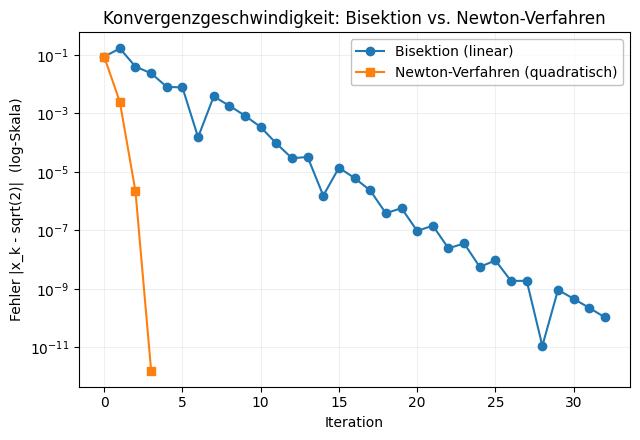

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('default')
plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'savefig.facecolor': 'white',
    'savefig.transparent': False,
    'axes.edgecolor': 'black',
    'axes.labelcolor': 'black',
    'axes.titlecolor': 'black',
    'xtick.color': 'black',
    'ytick.color': 'black',
    'text.color': 'black',
    'axes.grid': True,
    'grid.color': '0.8',
    'legend.facecolor': 'white',
    'legend.edgecolor': '0.7',
})


def f(x):
    return x ** 2 - 2


def f_strich(x):
    return 2 * x


EXAKT = np.sqrt(2)


def bisektion(f, a, b, tol=1e-10, max_iter=100):
    if f(a) * f(b) > 0:
        raise ValueError("f(a) und f(b) muessen unterschiedliches Vorzeichen haben")
    fehler = []
    for _ in range(max_iter):
        m = (a + b) / 2
        fehler.append(abs(m - EXAKT))
        if f(a) * f(m) <= 0:
            b = m
        else:
            a = m
        if (b - a) / 2 < tol:
            break
    return m, fehler


def newton(f, f_strich, x0, tol=1e-10, max_iter=100):
    x = x0
    fehler = [abs(x - EXAKT)]
    for _ in range(max_iter):
        x = x - f(x) / f_strich(x)
        fehler.append(abs(x - EXAKT))
        if fehler[-1] < tol:
            break
    return x, fehler


def main():
    print("Nullstellensuche fuer f(x) = x^2 - 2, exakte Loesung: sqrt(2) =", EXAKT)

    x_bisektion, err_bis = bisektion(f, 1.0, 2.0)
    x_newton, err_new = newton(f, f_strich, 1.5)

    print(f"\nBisektion:  {len(err_bis):3d} Iterationen -> x = {x_bisektion:.10f}")
    print(f"Newton:     {len(err_new)-1:3d} Iterationen -> x = {x_newton:.10f}")

    print("\nFehlerverlauf Bisektion (linear, Fehler etwa halbiert sich):")
    for i, e in enumerate(err_bis[:8]):
        print(f"  Iteration {i:2d}: Fehler = {e:.6e}")

    print("\nFehlerverlauf Newton (quadratisch, Anzahl gueltiger Stellen verdoppelt sich):")
    for i, e in enumerate(err_new[:8]):
        print(f"  Iteration {i:2d}: Fehler = {e:.6e}")

    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    ax.semilogy(range(len(err_bis)), err_bis, "o-", label="Bisektion (linear)")
    ax.semilogy(range(len(err_new)), err_new, "s-", label="Newton-Verfahren (quadratisch)")
    ax.set_xlabel("Iteration")
    ax.set_ylabel("Fehler |x_k - sqrt(2)|  (log-Skala)")
    ax.set_title("Konvergenzgeschwindigkeit: Bisektion vs. Newton-Verfahren")
    ax.legend()
    ax.grid(True, which="both", alpha=0.3)
    fig.tight_layout()
    plt.show()


if __name__ == "__main__":
    main()